# Data engineering: figures of Lesson 04.01

- This notebook generates the figures and tables of the slides
  `Lesson04.01_Data_Engineering.smd` from simulated data, and saves the
  figures as PNG files
- The running example is a value signal built on quarterly fundamentals, with
  release dates, restatements, delistings, splits, and dividends planted in
  the data
- The pedagogical arc:
  - Point-in-time correctness: as-of joins, release lags, and restatements
  - Survivorship bias: the delisting return that a database leaves out
  - Reference data: split and dividend adjustment, and time zones

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import pandas as pd

In [2]:
import helpers.hintrospection as hintros
import helpers.hmatplotlib as hmatplo
import helpers.hnotebook as hnotebook

import L04_01_data_engineering_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /Users/saggese/src/venv/client_venv.helpers/lib/python3.11/site-packages/ipykernel_launcher.py -f /private/var/folders/pd/0_nppqrn3cn7936mmhk37gcw0000gn/T/tmpctbg668m.json --HistoryManager.hist_file=:memory:


In [3]:
# Directory of the figures, and prefix of the markdown reference to paste in the
# slides.
out_dir_name = "figures"
markdown_path_prefix = "book_Modern_AI_for_Finance/lectures_source"

# Figure sizes: a single panel fits a column of a slide, two stacked panels
# need more height.
figsize = (6.0, 4.0)
figsize_tall = (6.0, 5.0)

# Seed of all the simulations.
seed = 4

# Part 1: Point-in-time correctness

## Cell 1.1: Simulate fundamentals with release dates and restatements

**Goal**
- Simulate the quarterly fundamentals of 1000 stocks over 15 years
- See that each record has a period end (`datadate`) and a later release date
  (`rdq`)
- See that some records are restated after the release

In [4]:
# Simulate the fundamentals of the running example.
fund_df = utils.simulate_fundamentals(
    n_stocks=1000,
    n_quarters=60,
    first_quarter_end="2005-03-31",
    persistence=0.9,
    restated_fraction=0.15,
    seed=seed,
)
print("fund_df.shape=", fund_df.shape)
display(fund_df.head())

fund_df.shape= (60000, 10)


,stock,datadate,rdq,lag_days,v,surprise,signal_first,restate_date,delta,signal_restated
0,S0000,2005-03-31,2005-05-07,37,-0.651791,-0.698771,-1.350562,NaT,0.0,-1.350562
1,S0000,2005-06-30,2005-08-17,48,-0.304157,-1.512517,-1.816674,NaT,0.0,-1.816674
2,S0000,2005-09-30,2005-11-06,37,-0.544518,0.281853,-0.262666,NaT,0.0,-0.262666
3,S0000,2005-12-31,2006-02-22,53,-1.269833,-0.501293,-1.771126,NaT,0.0,-1.771126
4,S0000,2006-03-31,2006-05-28,58,-1.711132,-0.933590,-2.644722,NaT,0.0,-2.644722


In [5]:
# Summarize the release lag, i.e., the days between the period end and the
# release.
print("lag_days.describe()=")
display(fund_df["lag_days"].describe())
print("share restated=", fund_df["restate_date"].notna().mean())

lag_days.describe()=


count    60000.000000
mean        58.764650
std         18.502094
min         25.000000
25%         45.000000
50%         56.000000
75%         69.000000
max        181.000000
Name: lag_days, dtype: float64

share restated= 0.15213333333333334


In [6]:
# Simulate the monthly returns that react to the news when it is released.
month_ends = utils.make_month_ends(fund_df, n_extra_months=8)
returns_df = utils.simulate_monthly_returns(
    fund_df,
    month_ends,
    monthly_drift=0.006,
    monthly_vol=0.08,
    dof=4.0,
    value_beta=0.003,
    surprise_beta=0.02,
    restate_beta=0.02,
    seed=seed,
)
print("returns_df.shape=", returns_df.shape)

returns_df.shape= (186, 1000)


## Cell 1.2: As-of join on a small example

**Goal**
- Join fundamentals to monthly decisions in two ways, on the period end and
  on the release date
- See that the only change is the key of the join, and that the first key
  uses numbers that were not public yet

In [7]:
# Build one stock with three quarters of fundamentals, and monthly decisions.
fund_small_df, decision_df = utils.build_asof_example()
display(fund_small_df)

,stock,datadate,rdq,earnings_yield
0,AAA,2023-12-31,2024-02-22,4.1
1,AAA,2024-03-31,2024-05-02,4.6
2,AAA,2024-06-30,2024-08-01,5.2


In [8]:
# Join on the period end: each decision takes the latest quarter that has
# already ended.
naive_df = pd.merge_asof(
    decision_df,
    fund_small_df,
    left_on="decision_date",
    right_on="datadate",
    by="stock",
)
display(naive_df)
# Outcome: on 2024-01-31 the decision uses the quarter ended 2023-12-31, but
# that quarter was released on 2024-02-22.

,stock,decision_date,datadate,rdq,earnings_yield
0,AAA,2024-01-31,2023-12-31,2024-02-22,4.1
1,AAA,2024-02-29,2023-12-31,2024-02-22,4.1
2,AAA,2024-03-31,2024-03-31,2024-05-02,4.6
3,AAA,2024-04-30,2024-03-31,2024-05-02,4.6
4,AAA,2024-05-31,2024-03-31,2024-05-02,4.6
5,AAA,2024-06-30,2024-06-30,2024-08-01,5.2
6,AAA,2024-07-31,2024-06-30,2024-08-01,5.2
7,AAA,2024-08-31,2024-06-30,2024-08-01,5.2


In [9]:
# Join on the release date: each decision takes the latest quarter that has
# already been released.
asof_df = pd.merge_asof(
    decision_df,
    fund_small_df,
    left_on="decision_date",
    right_on="rdq",
    by="stock",
)
display(asof_df)
# Outcome: on 2024-01-31 there is no value, and each value appears only after
# its release date.

,stock,decision_date,datadate,rdq,earnings_yield
0,AAA,2024-01-31,NaT,NaT,NaN
1,AAA,2024-02-29,2023-12-31,2024-02-22,4.1
2,AAA,2024-03-31,2023-12-31,2024-02-22,4.1
3,AAA,2024-04-30,2023-12-31,2024-02-22,4.1
4,AAA,2024-05-31,2024-03-31,2024-05-02,4.6
5,AAA,2024-06-30,2024-03-31,2024-05-02,4.6
6,AAA,2024-07-31,2024-03-31,2024-05-02,4.6
7,AAA,2024-08-31,2024-06-30,2024-08-01,5.2


## Cell 1.3: Release lag and look-ahead

**Goal**
- Measure the information coefficient (IC) of the value signal when the value
  is available a fixed lag after the period end
- Compare it with the IC when the value is available on the true release
  date
- See that a short lag assumption leaks the earnings news into the signal

In [10]:
# Compute the mean IC for each assumed lag after the quarter end.
lags = [0, 30, 45, 60, 75, 90, 105, 120]
ic_by_lag_s = utils.compute_ic_by_assumed_lag(
    fund_df, returns_df, lags=lags, min_stocks=500
)
display(ic_by_lag_s.to_frame())

,mean_ic
assumed_lag_days,
0,0.088546
30,0.089345
45,0.052822
60,0.046243
75,0.031518
90,0.031518
105,0.028691
120,0.028691


In [11]:
# Compute the mean IC when each value is available on its release date.
signal_asof_df = utils.build_signal(
    fund_df, month_ends, mode="first", assumed_lag_days=0
)
ic_asof_s = utils.compute_monthly_ic(
    signal_asof_df, returns_df, min_stocks=500
)
ic_asof = float(ic_asof_s.mean())
print("ic_asof=", ic_asof)

ic_asof= 0.029256225882320668


**Description**
- Inputs
  - `lags`: assumed days between the period end and the availability of the
    value
  - `ic_asof`: mean IC when the value is available on the true release date

- Panels
  - `Release lag`: histogram of the days between the period end and the
    release, with the mean in red
  - `IC by assumed lag`: mean IC against the assumed lag in blue, and the
    as-of IC as a green dashed line

Saved figure to 'figures/L04.01.Release_Lag.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L04.01.Release_Lag.png)


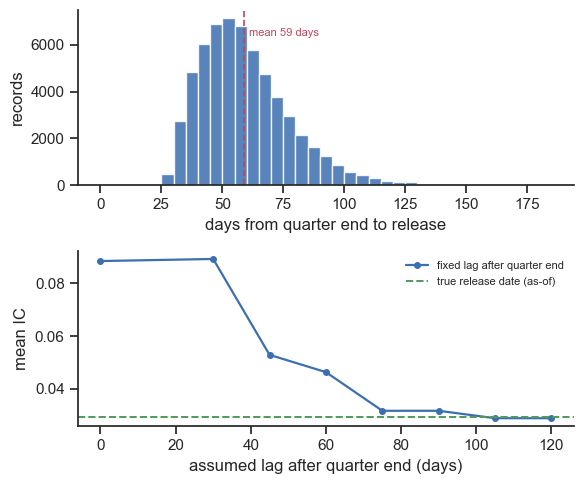

In [12]:
# Plot the release lags and the IC against the assumed lag.
fig = utils.cell1_3_plot_release_lag(
    fund_df, ic_by_lag_s, ic_asof, figsize=figsize_tall
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L04.01.Release_Lag.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Compare the IC at an assumed lag of 0 and 30 days with the IC at 120 days
  - Observe the IC fall to the as-of level only once the assumed lag exceeds
    almost all the true lags
- Compare the IC at an assumed lag of 45 days with the as-of line
  - Observe that a common rule of thumb still leaks the news of the slow
    reporters

**Implementation** `cell1_3_plot_release_lag()`
- Draws the histogram of `lag_days` and marks its mean
- Plots the mean IC of each assumed lag, computed by
  `compute_ic_by_assumed_lag()` with `build_signal(mode="period_end_lag")`
- Draws the IC with true release dates as a horizontal line

In [13]:
hintros.print_obj_info(utils.cell1_3_plot_release_lag)

- `cell1_3_plot_release_lag(fund_df: pandas.core.frame.DataFrame, ic_by_lag_s: pandas.core.series.Series, ic_asof: float, *, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the distribution of release lags and the IC against the assumed lag.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L04_data_engineering/L04_01_data_engineering_utils.py#L503


## Cell 1.4: Restatements and vintages

**Goal**
- Compare three ways to read a restated value: the latest vintage, the point
  in time vintage, and the first reported value
- See that the latest vintage knows the restatement before it happens, and
  inflates the IC

In [14]:
# Compute the mean IC of the signal under each vintage rule.
ic_by_vintage_s = utils.compute_ic_by_vintage_rule(
    fund_df, returns_df, min_stocks=500
)
display(ic_by_vintage_s.to_frame())

,mean_ic
latest vintage,0.043685
point in time,0.026647
first reported,0.029256


In [15]:
# Pick a restated record with a typical release lag.
record = utils.pick_restated_record(fund_df)
display(record.to_frame("record"))

,record
stock,S0272
datadate,2012-09-30 00:00:00
rdq,2012-11-25 00:00:00
lag_days,56
v,-0.214768
surprise,0.14731
signal_first,-0.067458
restate_date,2012-12-21 00:00:00
delta,-1.494744
signal_restated,-1.562202


**Description**
- Inputs
  - `record`: one restated record, with its period end, release date, and
    restatement date
  - `ic_by_vintage_s`: mean IC under each vintage rule

- Panels
  - `Vintages`: the value known at each date in blue, and the value that a
    database keeping only the latest vintage shows today in red
  - `IC by vintage rule`: mean IC of the latest vintage, the point in time
    vintage, and the first reported value

Saved figure to 'figures/L04.01.Restatements.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L04.01.Restatements.png)


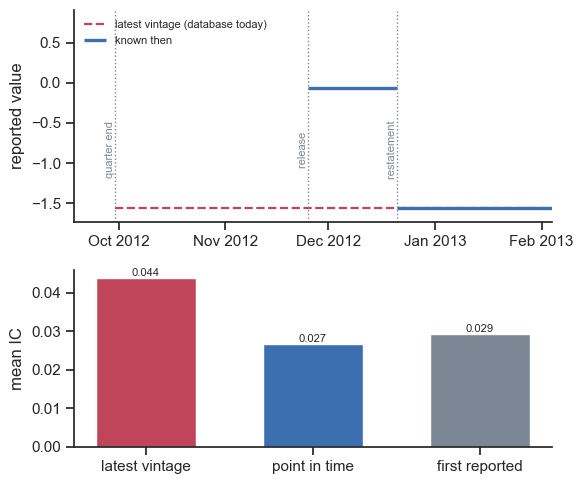

In [16]:
# Plot the vintages of one record and the IC of each vintage rule.
fig = utils.cell1_4_plot_restatements(
    record, ic_by_vintage_s, figsize=figsize_tall
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L04.01.Restatements.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Compare the red dashed line with the blue line before the restatement date
  - Observe that the latest vintage shows, from the quarter end, a value that
    nobody knew until the restatement
- Compare the first bar with the second bar
  - Observe the gain of the latest vintage over the point in time vintage:
    the revision predicts the price reaction that follows it

**Implementation** `cell1_4_plot_restatements()`
- Draws the value known between the release and the restatement, and the
  value known after the restatement, as solid blue segments
- Draws the restated value over the whole period as a red dashed segment
- Plots the three mean IC values as bars

In [17]:
hintros.print_obj_info(utils.cell1_4_plot_restatements)

- `cell1_4_plot_restatements(record: pandas.core.series.Series, ic_by_vintage_s: pandas.core.series.Series, *, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the vintages of one restated record and the IC of each vintage rule.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L04_data_engineering/L04_01_data_engineering_utils.py#L624


## Cell 1.5: A guard that fails loudly

**Goal**
- Check that every joined row was known before the decision
- See that the guard counts the future rows of the period end join, and
  passes on the as-of join

In [18]:
# Count the rows that use a value released after the decision.
n_future_naive = utils.count_future_records(
    naive_df, decision_col="decision_date", knowledge_col="rdq"
)
print("n_future_naive=", n_future_naive)
# Outcome: the period end join uses future values on five of the eight
# decisions.

n_future_naive= 5


In [19]:
# Assert that the as-of join has no future row; the same call on `naive_df`
# raises an error.
utils.assert_point_in_time(
    asof_df, decision_col="decision_date", knowledge_col="rdq"
)
n_future_asof = utils.count_future_records(
    asof_df, decision_col="decision_date", knowledge_col="rdq"
)
print("n_future_asof=", n_future_asof)

n_future_asof= 0


# Part 2: Survivorship bias

## Cell 2.1: The delisting return

**Goal**
- Simulate stocks that delist for performance reasons, cheap stocks more
  often
- Compare the return of the cheapness deciles when the delisting return is
  true, missing, or imputed
- See that a missing delisting return inflates the value premium

In [20]:
# Simulate the monthly returns of 3000 stocks over 20 years, with delistings.
returns_del_df, is_delisting_df, cheapness_s = utils.simulate_delisting_panel(
    n_stocks=3000,
    n_months=240,
    base_hazard=0.0015,
    hazard_slope=1.0,
    premium_slope=0.0012,
    mean_delisting_return=-0.30,
    delisting_vol=0.25,
    seed=seed,
)
print("returns_del_df.shape=", returns_del_df.shape)
print("share delisted=", (is_delisting_df.sum() > 0).mean())

returns_del_df.shape= (240, 3000)
share delisted= 0.3616666666666667


In [21]:
# Compute the annual return of each cheapness decile under each rule for the
# delisting month.
decile_df = pd.DataFrame(
    {
        rule: utils.compute_decile_returns(
            returns_del_df,
            is_delisting_df,
            cheapness_s,
            delisting_rule=rule,
            imputed_return=-0.30,
        )
        for rule in ["true", "missing", "imputed"]
    }
)
display((100 * decile_df).round(2))

,true,missing,imputed
decile,,,
1,6.04,6.11,6.04
2,6.49,6.74,6.45
3,6.86,7.11,6.87
4,6.88,7.30,6.93
5,8.07,8.42,8.04
6,7.71,8.38,7.75
7,7.95,8.86,8.00
8,8.59,9.62,8.46
9,8.17,9.99,8.26


**Description**
- Inputs
  - `mean_delisting_return`: mean return of the delisting month, -30%
  - `base_hazard`, `hazard_slope`: monthly probability of delisting, and how
    fast it grows with cheapness
  - `imputed_return`: return used when the delisting return is missing, -30%

- Panels
  - `Delisting returns`: histogram of the return of the delisting months,
    with the mean in red
  - `Decile returns`: annual return of the ten cheapness deciles with the true
    delisting return in blue, missing in red, and imputed in green

Saved figure to 'figures/L04.01.Delisting_Returns.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L04.01.Delisting_Returns.png)


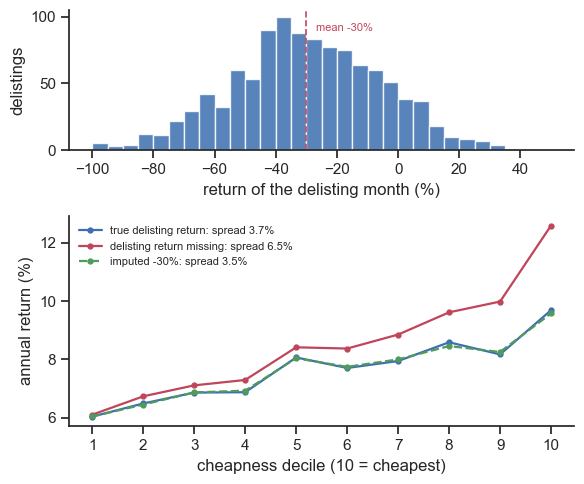

In [22]:
# Plot the delisting returns and the decile returns.
delisting_returns = returns_del_df.to_numpy()[is_delisting_df.to_numpy()]
fig = utils.cell2_1_plot_delisting_returns(
    delisting_returns, decile_df, figsize=figsize_tall
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L04.01.Delisting_Returns.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Compare the red and the blue curves at decile 10
  - Observe that the missing delisting returns raise the return of the
    cheapest decile, where most delistings happen
- Compare the spread in the legend of the three rules
  - Observe that the imputed return recovers most of the true spread

**Implementation** `cell2_1_plot_delisting_returns()`
- Plots the histogram of the returns of the delisting months
- Plots the annual return of each decile under the three rules, computed by
  `compute_decile_returns()`, and writes the spread of decile 10 minus
  decile 1 in the legend

In [23]:
hintros.print_obj_info(utils.cell2_1_plot_delisting_returns)

- `cell2_1_plot_delisting_returns(delisting_returns: numpy.ndarray, decile_df: pandas.core.frame.DataFrame, *, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the delisting returns and the decile returns under each rule.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L04_data_engineering/L04_01_data_engineering_utils.py#L861


# Part 3: Reference data

## Cell 3.1: Split and dividend adjustment

**Goal**
- Simulate the raw prices of a stock with quarterly dividends and splits
- Adjust the prices for splits and dividends
- See the gap between the price-only return and the total return

In [24]:
# Simulate 20 years of raw prices with dividends and splits.
price_df = utils.simulate_dividend_payer(
    n_years=20,
    start_price=60.0,
    annual_drift=0.11,
    annual_vol=0.25,
    quarterly_yield=0.005,
    split_price=120.0,
    split_ratio=2,
    seed=3,
)
print("number of splits=", (price_df["split_ratio"] > 1).sum())
print("number of dividends=", (price_df["dividend"] > 0).sum())

number of splits= 2
number of dividends= 80


In [25]:
# Adjust the raw prices, and compare the worst daily return before and after.
adjusted_df = utils.adjust_prices(price_df)
print("worst raw return=", price_df["close"].pct_change().min())
print("worst adjusted return=", adjusted_df["fully_adjusted"].pct_change().min())

worst raw return= -0.48987421086455885
worst adjusted return= -0.05122654947153238


**Description**
- Inputs
  - `quarterly_yield`: dividend over the previous close, 0.5% each quarter
  - `split_price`, `split_ratio`: raw close above which the stock splits 2 for
    1

- Panels
  - `Growth of $1`: value of $1 invested at the start with dividends
    reinvested in blue, and with the price only in red
  - `Adjustment factor`: factor that turns the raw close into the adjusted
    close, for splits and dividends in blue and for splits only in orange

Saved figure to 'figures/L04.01.Adjusted_Prices.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L04.01.Adjusted_Prices.png)


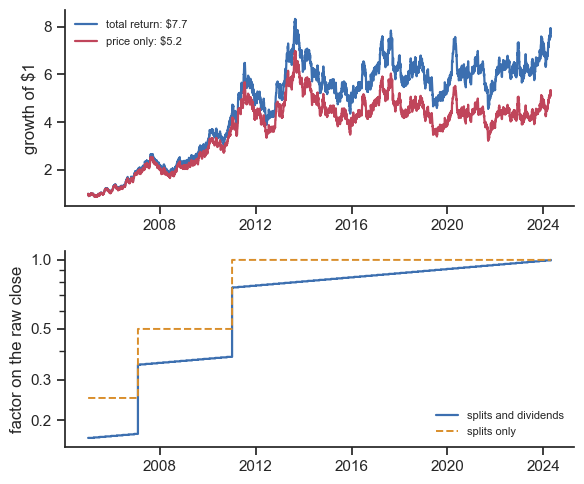

In [26]:
# Plot the growth of $1 and the adjustment factor.
fig = utils.cell3_1_plot_adjusted_prices(adjusted_df, figsize=figsize_tall)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L04.01.Adjusted_Prices.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Compare the two curves in the top panel at the last date
  - Observe the gap: the dividends that the price-only series leaves out
- Follow the blue and the orange lines in the bottom panel
  - Observe the large steps at the splits and the small steps at the
    dividends

**Implementation** `cell3_1_plot_adjusted_prices()`
- Rescales the split-adjusted and the fully adjusted closes to start at 1
- Plots the factors computed by `adjust_prices()` as step functions on a log
  scale

In [27]:
hintros.print_obj_info(utils.cell3_1_plot_adjusted_prices)

- `cell3_1_plot_adjusted_prices(adjusted_df: pandas.core.frame.DataFrame, *, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot price-only vs total-return growth and the adjustment factor.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L04_data_engineering/L04_01_data_engineering_utils.py#L1035


## Cell 3.2: The price on a past date, as known and as adjusted today

**Goal**
- Compare the close that traded on a past date with the close that a
  database built today shows for that date
- See that adjusted prices change every time a new split or dividend
  happens

In [28]:
# Compare the raw and the adjusted close on one past date.
adjustment_df = utils.make_adjustment_table(adjusted_df, "2010-06-30")
display(adjustment_df)
# Outcome: the stock traded at about 98 dollars, and today's database shows
# about 37 dollars for the same day.

,price,total_factor
raw close on 2010-06-30,97.843613,1.00000
split-adjusted close,48.921807,0.50000
fully adjusted close,36.579787,0.37386


## Cell 3.3: Time zones and daylight saving

**Goal**
- Convert the same local close, 16:00 in New York, to UTC over two years
- Measure the gap between New York and London, which is not constant
- List the local days that do not have 24 hours

In [29]:
# Compute the UTC hour of the New York close and the New York / London gap.
close_df = utils.compute_close_in_utc("2024-01-01", "2025-12-31")
print("days by UTC hour of the close=")
display(close_df["ny_close_utc_hour"].value_counts())

days by UTC hour of the close=


ny_close_utc_hour
20    476
21    255
Name: count, dtype: int64

In [30]:
# Count the days per year where the gap is 4 hours instead of 5.
off_df = close_df[close_df["ny_minus_london_hours"] != 5.0]
print("days with a different gap, by year=")
display(off_df.groupby(pd.DatetimeIndex(off_df.index).year).size())
print("first and last day of the first window=")
print(off_df.index[0], off_df.index[off_df.index < "2024-06-01"][-1])

days with a different gap, by year=


2024    28
2025    28
dtype: int64

first and last day of the first window=
2024-03-10 00:00:00 2024-03-30 00:00:00


In [31]:
# List the local days with 23 or 25 hours in 2024.
print("New York=")
display(
    utils.list_non_24_hour_days(
        "2024-01-01", "2024-12-31", time_zone="America/New_York"
    )
)
print("London=")
display(
    utils.list_non_24_hour_days(
        "2024-01-01", "2024-12-31", time_zone="Europe/London"
    )
)

New York=


2024-03-10    23.0
2024-11-03    25.0
dtype: float64

London=


2024-03-31    23.0
2024-10-27    25.0
dtype: float64

**Description**
- Inputs
  - `start`, `end`: first and last calendar day of the table

- Panels
  - `UTC hour of the close`: UTC hour of 16:00 in New York, 21 in winter and
    20 in summer
  - `New York minus London`: gap in hours between noon in New York and noon
    in London, shaded in gray on the days where it is not 5

Saved figure to 'figures/L04.01.UTC_Close.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L04.01.UTC_Close.png)


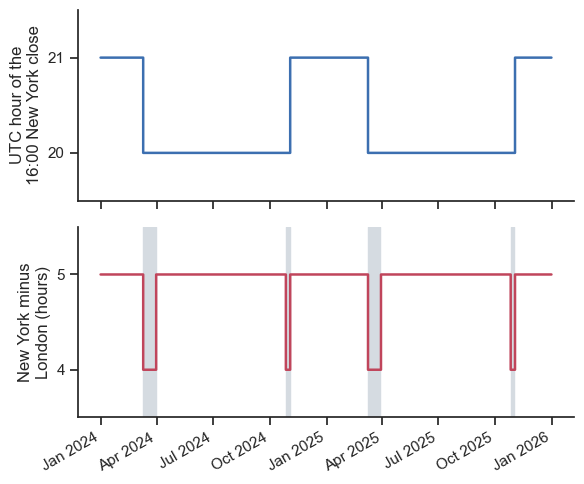

In [32]:
# Plot the UTC hour of the close and the New York / London gap.
fig = utils.cell3_3_plot_utc_close(close_df, figsize=figsize_tall)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L04.01.UTC_Close.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Follow the top line across the two clock changes of each year
  - Observe that the same local close moves by one hour in UTC
- Look at the gray bands in the bottom panel
  - Observe that the gap between the two cities drops to 4 hours for about
    4 weeks a year, since the clocks change on different dates

**Implementation** `cell3_3_plot_utc_close()`
- Localizes 16:00 and noon in each city with the time zone database, and
  converts them to UTC
- Plots the UTC hour of the close and the gap as step functions

In [33]:
hintros.print_obj_info(utils.cell3_3_plot_utc_close)

- `cell3_3_plot_utc_close(close_df: pandas.core.frame.DataFrame, *, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the UTC hour of the New York close and the New York / London gap.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L04_data_engineering/L04_01_data_engineering_utils.py#L1195
